# Naive Seam Carving

The naive approach applies seam carving independently on each and every frame. The resultant frames are then stiched together. Temporal information is not considered in this approach.

In [1]:
import cv2
import numpy as np 
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
# Input video
# input_video = "../assets/input/golf.mov"    # (83, 240, 320, 3)
input_video = "../assets/input/ratatouille1.mov"    # (64, 256, 640, 3)

In [3]:
cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    print(f"Could not open {input_video}")
else: 
    frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(frame)

cap.release()

# This will print (T, H, W, C) 
frames = frames[:60]    # Using only first 60 frames
print(f"Video shape: ({len(frames)}, {frames[0].shape[0]}, {frames[0].shape[1]}, {frames[0].shape[2]})")

Video shape: (60, 256, 640, 3)


In [4]:
def backward_energy(img, visualize=False):
    """
    Energy map using sobel filter
    """
    xgrad = cv2.Sobel(img, cv2.CV_32F, dx=1, dy=0, ksize=3, borderType=cv2.BORDER_DEFAULT)
    ygrad = cv2.Sobel(img, cv2.CV_32F, dx=0, dy=1, ksize=3, borderType=cv2.BORDER_DEFAULT)
    back_energy = np.sqrt(np.sum(xgrad**2, axis=2) + np.sum(ygrad**2, axis=2))

    if (visualize):
        # cv2.imwrite("backward_energy.jpg", back_energy)
        plt.imshow(back_energy, cmap="gray")
        plt.show()

    return back_energy

In [5]:
def forward_energy(img, visualize=False):
    """
    Energy map using backward energy and the intensity difference created by removing the pixel
    """

    back_energy = backward_energy(img)

    for_energy = back_energy.copy()

    for i in range(1, img.shape[0]):
        for j in range(img.shape[1]):

            if (j == 0):    # Here, we can only account for top and right
                cU = for_energy[i-1, j]
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cU, cR)

            elif (j == img.shape[1] - 1):    # Here, we can only account for top and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                min_cost = min(cU, cL)

            else:    # Here, we can account for top, right and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cL, cU, cR)
        
            for_energy[i][j] += min_cost
    
    if (visualize):
        for_energy = cv2.normalize(for_energy, None, 0, 255, cv2.NORM_MINMAX)
        plt.imshow(for_energy, cmap="gray")
        plt.show()

    return for_energy

In [6]:
# back_energy = backward_energy(frames[0], visualize=True)
# for_energy = forward_energy(frames[0], visualize=True)

In [7]:
# forward_energy_maps = []
# backward_energy_maps = []

# for frame in frames:
#     for_energy = forward_energy(frame)
#     back_energy = backward_energy(frame)

#     forward_energy_maps.append(for_energy)
#     backward_energy_maps.append(back_energy)

In [8]:
# # Create the video for energy maps 
# def normalize_for_video(energy_maps):
#     norm_maps = []
#     for e in energy_maps:
#         norm_e = cv2.normalize(e, None, 0, 255, cv2.NORM_MINMAX)
#         norm_maps.append(norm_e.astype(np.uint8))
#     return norm_maps

# forward_video_maps = normalize_for_video(forward_energy_maps)
# backward_video_maps = normalize_for_video(backward_energy_maps)

# h, w = forward_video_maps[0].shape
# fps = 30 

# fourcc = cv2.VideoWriter_fourcc(*'mp4v')
# forward_out = cv2.VideoWriter('../assets/output/extras/forward_energy_video.mp4', fourcc, fps, (w, h), isColor=False)
# backward_out = cv2.VideoWriter('../assets/output/extras/backward_energy_video.mp4', fourcc, fps, (w, h), isColor=False)

# for f_frame, b_frame in zip(forward_video_maps, backward_video_maps):
#     forward_out.write(f_frame)
#     backward_out.write(b_frame)

# forward_out.release()
# backward_out.release()

In [9]:
def find_vertical_seam(energy_map):
    energy = energy_map.copy()
    backtrack = np.zeros(energy.shape, dtype=np.int32)

    for i in range(1, energy.shape[0]):
        left = energy[i-1, :-2]
        middle = energy[i-1, 1:-1]
        right = energy[i-1, 2:]

        left = np.pad(left, (1,1), constant_values=np.inf)
        middle = np.pad(middle, (1,1), constant_values=np.inf)
        right = np.pad(right, (1,1), constant_values=np.inf)

        prev = np.vstack([left, middle, right])   
        choices = np.argmin(prev, axis=0)
        backtrack[i] = np.arange(energy.shape[1]) + (choices - 1)

        energy[i] += prev[choices, np.arange(energy.shape[1])]
        
    seam = np.zeros(energy.shape[0], dtype=np.int32)
    seam[-1] = np.argmin(energy[-1])

    for i in range(energy.shape[0]-2, -1, -1):
        seam[i] = backtrack[i+1, seam[i+1]]

    return seam

# Horizontal seam for A is nothing but vertical seam for A
def find_horizontal_seam(energy):
    return find_vertical_seam(energy.T)

In [10]:
def visualize_vertical_seam(img, seam):
    visualization_img = img.copy()
    for i in range(len(seam)):
        j_start = seam[i]    # This is the pixel to be colored
        visualization_img[i, j_start, :] = (255, 0, 0)    # Red for columns
    return visualization_img


def visualize_horizontal_seam(img, seam):
    visualization_img = img.copy()
    for i in range(len(seam)):
        i_start = seam[i]    # This is the pixel to be colored
        visualization_img[i_start, i, :] = (0, 0, 255)
    return visualization_img


In [11]:
def remove_vertical_seam(img, seam):
    h, w, c = img.shape
    out = np.zeros((h, w-1, c), dtype=img.dtype)
    for i in range(h):
        j = seam[i]
        out[i, :, :] = np.delete(img[i, :, :], j, axis=0)
    return out

def remove_horizontal_seam(img, seam):
    h, w, c = img.shape
    out = np.zeros((h-1, w, c), dtype=img.dtype)
    for j in range(w):
        i = seam[j]
        out[:, j, :] = np.delete(img[:, j, :], i, axis=0)
    return out

In [12]:
def resize(img, target_h, target_w, visualize = False):
    modified_img = img.copy()
    num_vertical_seams = img.shape[1] - target_w
    num_horizontal_seams = img.shape[0] - target_h

    if (visualize):
        visualization_frames = []

    while (num_vertical_seams > 0) or (num_horizontal_seams > 0):
        energy = forward_energy(modified_img)

        if (num_horizontal_seams == 0):
            seam = find_vertical_seam(energy)
            if (visualize):
                visualization_img = visualize_vertical_seam(modified_img, seam)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)    # For visualization in form of video
                visualization_frames.append(visualization_resized)
            modified_img = remove_vertical_seam(modified_img, seam)
            num_vertical_seams -= 1

        elif (num_vertical_seams == 0):
            seam = find_vertical_seam(energy.T)    # Horizontal seam for A is nothing but vertical seam for A.
            if (visualize):
                visualization_img = visualize_horizontal_seam(modified_img, seam)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                visualization_frames.append(visualization_resized)
            modified_img = remove_horizontal_seam(modified_img, seam)
            num_horizontal_seams -= 1
        
        else:
            vertical_seam = find_vertical_seam(energy)
            vertical_cost = energy[np.arange(len(vertical_seam)), vertical_seam].sum()
            horizontal_seam = find_vertical_seam(energy.T)
            horizontal_cost = energy.T[np.arange(len(horizontal_seam)), horizontal_seam].sum()

            if (vertical_cost <= horizontal_cost):
                seam = vertical_seam
                if (visualize):
                    visualization_img = visualize_vertical_seam(modified_img, seam)
                    visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)    # For visualization in form of video
                    visualization_frames.append(visualization_resized)
                modified_img = remove_vertical_seam(modified_img, seam)
                num_vertical_seams -= 1
            else:
                seam = horizontal_seam    
                if (visualize):
                    visualization_img = visualize_horizontal_seam(modified_img, seam)
                    visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                    visualization_frames.append(visualization_resized)
                modified_img = remove_horizontal_seam(modified_img, seam)
                num_horizontal_seams -= 1
            
    if (visualize):
        return modified_img, visualization_frames
    else:
        return modified_img

(256, 640, 3)


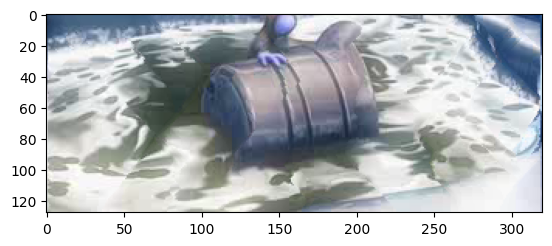

In [13]:
# Testing on one image
print(frames[0].shape)
modified_img, visualization_frames = resize(frames[0], 128, 320, visualize = True)

plt.imshow(modified_img)
plt.show()

In [14]:
def save_video(frames, output_path, fps=30):
    h, w, c = frames[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(output_path, fourcc, fps, (w, h), isColor=True)

    for f in frames:
        writer.write(f)
    writer.release()
    
    print(f"Saved output video to {output_path}")

In [15]:
save_video(visualization_frames, "../assets/output/extras/example_naive_seam_carving_output_ratouille1.mp4", fps=10)

Saved output video to ../assets/output/extras/example_naive_seam_carving_output_ratouille1.mp4


In [16]:
# Running naive seam carving for all frames
modified_frames = []
visualization_frames = []
target_h = 128    #200
target_w = 320    #200

for frame in tqdm(frames):
    modified_frame = resize(frame, target_h, target_w)
    modified_frames.append(modified_frame)

100%|██████████| 60/60 [4:44:48<00:00, 284.81s/it]  


In [ ]:
save_video(modified_frames, "../assets/output/seam_carving/naive_approach/naive_seam_carving_output_ratouille1.mp4", fps=30)

Saved output video to ../assets/output/naive_seam_carving_output_ratouille1.mp4
